/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/tmp/ipykernel_994/150363768.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  q_values[action] += (reward - q_values[action]) / counts[action]


Number of arms : 10

Epsilon-Greedy Results
Q-values: [-1.64 -0.33 -0.07 -0.36 -0.07 -1.61 -0.01 -0.32 -0.11 -0.47]
Arm selection counts: [  3   5   9  18 201   3 243   3   9   6]
Average reward: -0.08120388581977353


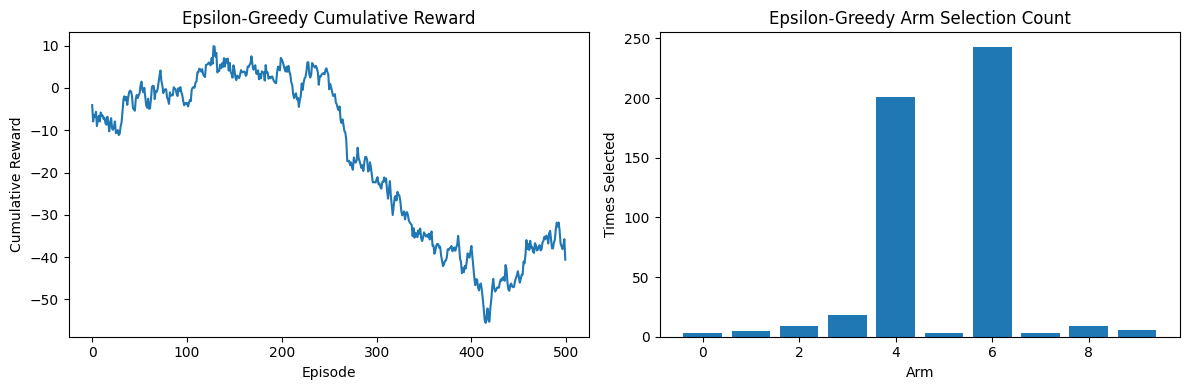


Softmax Results
Q-values: [-3.2   0.13 -0.31  0.13 -0.09  0.13 -0.43  0.25  0.25 -0.34]
Arm selection counts: [ 1 63 44 61 64 78 35 56 71 27]
Average reward: 0.02382652100760156


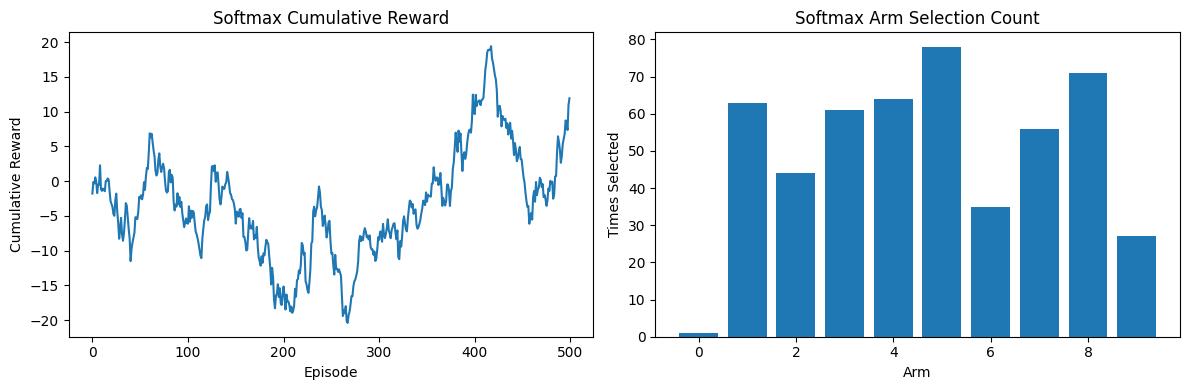

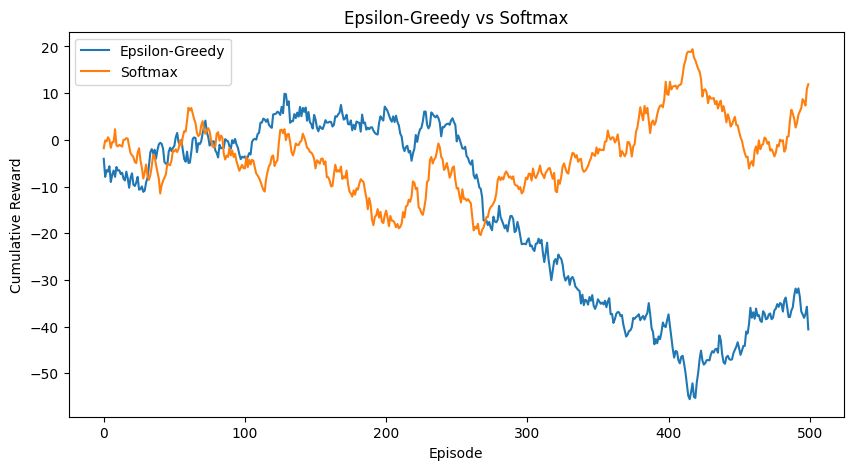

In [9]:
!pip install gym gym_bandits
import gym
import gym_bandits
import numpy as np
import matplotlib.pyplot as plt
np.bool8  = np.bool_
base_env = gym.make("MultiarmedBandits-v0")
env = base_env.unwrapped
n_arms = env.action_space.n
episodes = 500
print("Number of arms :", n_arms)
epsilon = 0.1
q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
rewards = []
for episode in range(episodes):
  env.reset()
  if np.random.rand() < epsilon: action = env.action_space.sample()
  else : action = np.argmax(q_values)
  observation, reward, done, info = env.step(action)
  counts[action]+=1
  q_values[action] += (reward - q_values[action]) / counts[action]
  rewards.append(reward)
print("\nEpsilon-Greedy Results")
print("Q-values:", np.round(q_values, 2))
print("Arm selection counts:", counts.astype(int))
print("Average reward:", np.mean(rewards))
plt.figure(figsize = (12,4))
plt.subplot(1,2,1)
plt.plot(np.cumsum(rewards))
plt.title("Epsilon-Greedy Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts)
plt.title("Epsilon-Greedy Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()
temperature = 0.5
q_values_softmax = np.zeros(n_arms)
counts_softmax = np.zeros(n_arms)
rewards_softmax = []
for episode in range(episodes):
    env.reset()
    probabilities = np.exp(q_values_softmax / temperature)
    probabilities = probabilities / np.sum(probabilities)
    action = np.random.choice(n_arms, p=probabilities)
    observation, reward, done, info = env.step(action)
    counts_softmax[action] += 1
    q_values_softmax[action] += (reward - q_values_softmax[action]) / counts_softmax[action]
    rewards_softmax.append(reward)
print("\nSoftmax Results")
print("Q-values:", np.round(q_values_softmax, 2))
print("Arm selection counts:", counts_softmax.astype(int))
print("Average reward:", np.mean(rewards_softmax))
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards_softmax))
plt.title("Softmax Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts_softmax)
plt.title("Softmax Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()
plt.figure(figsize=(10,5))
plt.plot(
    np.cumsum(rewards), label="Epsilon-Greedy"
)
plt.plot(
    np.cumsum(rewards_softmax), label="Softmax"
)
plt.title("Epsilon-Greedy vs Softmax")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.legend()
plt.show()
env.close()